In [1]:
using VoronoiMeshes, DelaunayTriangulation, NCDatasets, LinearAlgebra, JLD2
include("juliaDEC.jl");
@load "lsq_matrices.jld2" matrices_regular matrices_irregular

2-element Vector{Symbol}:
 :matrices_regular
 :matrices_irregular

In [ ]:
error_lap_diagonal_linf = []
error_lap_lsq1_linf = []
error_lap_lsq2_linf = []
error_lap_diagonal_l2 = []
error_lap_lsq1_l2 = []
error_lap_lsq2_l2 = []

order_lap_diagonal_linf = []
order_lap_lsq1_linf = []
order_lap_lsq2_linf = []
order_lap_diagonal_l2 = []
order_lap_lsq1_l2 = []
order_lap_lsq2_l2 = []
edge_length_list = []
for i = 1:7
    mesh = VoronoiMesh("meshes/mesh" * string(i) * "_regular.nc")
    println("-----------------------------------------------------------")
    println("vertices = ", mesh.vertices.n, "    cells = ", mesh.cells.n, "     edges = ", mesh.edges.n)
    xp = mesh.x_period
    yp = mesh.y_period
    u = x -> sin(8*pi*x[1]/xp) * sin(8*pi*x[2]/yp)
    true_laplacian = x -> -64*(pi^2)*sin(8*pi*x[1]/xp) * sin(8*pi*x[2]/yp)*(xp^(-2) + yp^(-2))

    u_cochain = Cochain(u.(mesh.cells.position), 0, true)
    lap_cochain = Cochain(true_laplacian.(mesh.cells.position), 0, true)
    f = lap_cochain.values
    F = sum(mesh.cells.area .* f)
    sum_areas = sum(mesh.cells.area)
    f .-= F/sum_areas

    d0 = d0_matrix_primal(mesh)
    d1 = d1_matrix_dual(mesh)
    star1_diagonal = star(mesh, 1, true)
    star1_lsq1 = matrices_regular[i]["lsq_linear"]
    star1_lsq2 = matrices_regular[i]["lsq_quadratic"]
    #star1_lsq1 = 0.5*(star1_lsq1 + star1_lsq1')
    #star1_lsq2 = 0.5*(star1_lsq2 + star1_lsq2')
    star2 = star(mesh, 2, false)

    A_diagonal = star2 * d1 * star1_diagonal * d0
    A_lsq1 = star2 * d1 * star1_lsq1 * d0
    A_lsq2 = star2 * d1 * star1_lsq2 * d0
    
    u_lap_diagonal = A_diagonal \ f
    u_lap_lsq1 = A_lsq1 \ f
    u_lap_lsq2 = A_lsq2 \ f
    u_lap_diagonal .-= sum(u_lap_diagonal .* mesh.cells.area)/sum_areas
    u_lap_lsq1 .-= sum(u_lap_lsq1 .* mesh.cells.area)/sum_areas
    u_lap_lsq2 .-= sum(u_lap_lsq2 .* mesh.cells.area)/sum_areas
    u_lap_diagonal = Cochain(u_lap_diagonal, 0, true)
    u_lap_lsq1 = Cochain(u_lap_lsq1, 0, true)
    u_lap_lsq2 = Cochain(u_lap_lsq2, 0, true)
    
    push!(error_lap_diagonal_l2, norm(u_lap_diagonal.values - u_cochain.values)*maximum(sqrt.(mesh.cells.area)))
    push!(error_lap_lsq1_l2, norm(u_lap_lsq1.values - u_cochain.values)*maximum(sqrt.(mesh.cells.area)))
    push!(error_lap_lsq2_l2, norm(u_lap_lsq2.values - u_cochain.values)*maximum(sqrt.(mesh.cells.area)))
    push!(error_lap_diagonal_linf, maximum(abs.(u_lap_diagonal.values - u_cochain.values)))
    push!(error_lap_lsq1_linf, maximum(abs.(u_lap_lsq1.values - u_cochain.values)))
    push!(error_lap_lsq2_linf, maximum(abs.(u_lap_lsq2.values - u_cochain.values)))
    push!(edge_length_list, maximum(sqrt.(mesh.cells.area)))
    println("Error Linf Diagonal = ", error_lap_diagonal_linf[end])
    println("Error Linf LSQ1 = ", error_lap_lsq1_linf[end])
    println("Error Linf LSQ2 = ", error_lap_lsq2_linf[end])
    println("Error L2 Diagonal = ", error_lap_diagonal_l2[end])
    println("Error L2 LSQ1 = ", error_lap_lsq1_l2[end])
    println("Error L2 LSQ2 = ", error_lap_lsq2_l2[end])
    if i > 1
        println("i = ", i)
        push!(order_lap_diagonal_linf, log(error_lap_diagonal_linf[end]/error_lap_diagonal_linf[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_lsq1_linf, log(error_lap_lsq1_linf[end]/error_lap_lsq1_linf[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_lsq2_linf, log(error_lap_lsq2_linf[end]/error_lap_lsq2_linf[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_diagonal_l2, log(error_lap_diagonal_l2[end]/error_lap_diagonal_l2[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_lsq1_l2, log(error_lap_lsq1_l2[end]/error_lap_lsq1_l2[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_lsq2_l2, log(error_lap_lsq2_l2[end]/error_lap_lsq2_l2[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
    end
end

println("order_lap_diagonal_Linf = ", order_lap_diagonal_linf)
println("order_lap_lsq1_Linf = ", order_lap_lsq1_linf)
println("order_lap_lsq2_Linf = ", order_lap_lsq2_linf)
println("order_lap_diagonal_l2 = ", order_lap_diagonal_l2)
println("order_lap_lsq1_l2 = ", order_lap_lsq1_l2)
println("order_lap_lsq2_l2 = ", order_lap_lsq2_l2)


-----------------------------------------------------------
vertices = 24    cells = 12     edges = 36
Error Linf Diagonal = 7.087165945792728
Error Linf LSQ1 = 26.478991463669797
Error Linf LSQ2 = 16.854727112319168
Error L2 Diagonal = 5.01482236321337
Error L2 LSQ1 = 18.736324700970382
Error L2 LSQ2 = 11.926272020309582
-----------------------------------------------------------
vertices = 96    cells = 48     edges = 144
Error Linf Diagonal = 3.417747112113933
Error Linf LSQ1 = 10.448692944342183
Error Linf LSQ2 = 3.7603042300788485
Error L2 Diagonal = 2.4183708024704478
Error L2 LSQ1 = 7.393409459666946
Error L2 LSQ2 = 2.660761523007252
i = 2
-----------------------------------------------------------
vertices = 384    cells = 192     edges = 576
Error Linf Diagonal = 0.6306386542232996
Error Linf LSQ1 = 6.292613285176742
Error Linf LSQ2 = 0.5877643407731419
Error L2 Diagonal = 0.33996633217120087
Error L2 LSQ1 = 3.3922383569917725
Error L2 LSQ2 = 0.31685353526827337
i = 3
--------

In [134]:
fig = Figure()
ax = Axis(fig[1,1])
plot_cochain!(ax, u_lap, mesh)
CairoMakie.save("laplacian_cochain.png", fig)


CairoMakie.Screen{IMAGE}


In [8]:
error_lap_diagonal_linf = []
error_lap_lsq1_linf = []
error_lap_lsq2_linf = []
error_lap_diagonal_l2 = []
error_lap_lsq1_l2 = []
error_lap_lsq2_l2 = []

order_lap_diagonal_linf = []
order_lap_lsq1_linf = []
order_lap_lsq2_linf = []
order_lap_diagonal_l2 = []
order_lap_lsq1_l2 = []
order_lap_lsq2_l2 = []
edge_length_list = []
for i = 1:7
    mesh = VoronoiMesh("meshes/mesh" * string(i) * ".nc")
    println("-----------------------------------------------------------")
    println("vertices = ", mesh.vertices.n, "    cells = ", mesh.cells.n, "     edges = ", mesh.edges.n)
    xp = mesh.x_period
    yp = mesh.y_period
    u = x -> cos(8*pi*x[1]/xp) * cos(8*pi*x[2]/yp)
    true_laplacian = x -> -64*(pi^2)*cos(8*pi*x[1]/xp) * cos(8*pi*x[2]/yp)*(xp^(-2) + yp^(-2))

    u_cochain = Cochain(u.(mesh.cells.position), 0, true)
    lap_cochain = Cochain(true_laplacian.(mesh.cells.position), 0, true)
    f = lap_cochain.values
    F = sum(mesh.cells.area .* f)
    sum_areas = sum(mesh.cells.area)
    f .-= F/sum_areas

    d0 = d0_matrix_primal(mesh)
    d1 = d1_matrix_dual(mesh)
    star1_diagonal = star(mesh, 1, true)
    star1_lsq1 = matrices_irregular[i]["lsq_linear"]
    star1_lsq2 = matrices_irregular[i]["lsq_quadratic"]
    #star1_lsq1 = 0.5*(star1_lsq1 + star1_lsq1')
    #star1_lsq2 = 0.5*(star1_lsq2 + star1_lsq2')
    star2 = star(mesh, 2, false)

    A_diagonal = star2 * d1 * star1_diagonal * d0
    A_lsq1 = star2 * d1 * star1_lsq1 * d0
    A_lsq2 = star2 * d1 * star1_lsq2 * d0
    
    u_lap_diagonal = A_diagonal \ f
    u_lap_lsq1 = A_lsq1 \ f
    u_lap_lsq2 = A_lsq2 \ f
    u_lap_diagonal .-= sum(u_lap_diagonal .* mesh.cells.area)/sum_areas
    u_lap_lsq1 .-= sum(u_lap_lsq1 .* mesh.cells.area)/sum_areas
    u_lap_lsq2 .-= sum(u_lap_lsq2 .* mesh.cells.area)/sum_areas
    u_lap_diagonal = Cochain(u_lap_diagonal, 0, true)
    u_lap_lsq1 = Cochain(u_lap_lsq1, 0, true)
    u_lap_lsq2 = Cochain(u_lap_lsq2, 0, true)
    
    push!(error_lap_diagonal_l2, norm(u_lap_diagonal.values - u_cochain.values)*maximum(sqrt.(mesh.cells.area)))
    push!(error_lap_lsq1_l2, norm(u_lap_lsq1.values - u_cochain.values)*maximum(sqrt.(mesh.cells.area)))
    push!(error_lap_lsq2_l2, norm(u_lap_lsq2.values - u_cochain.values)*maximum(sqrt.(mesh.cells.area)))
    push!(error_lap_diagonal_linf, maximum(abs.(u_lap_diagonal.values - u_cochain.values)))
    push!(error_lap_lsq1_linf, maximum(abs.(u_lap_lsq1.values - u_cochain.values)))
    push!(error_lap_lsq2_linf, maximum(abs.(u_lap_lsq2.values - u_cochain.values)))
    push!(edge_length_list, maximum(sqrt.(mesh.cells.area)))
    println("Error Linf Diagonal = ", error_lap_diagonal_linf[end])
    println("Error Linf LSQ1 = ", error_lap_lsq1_linf[end])
    println("Error Linf LSQ2 = ", error_lap_lsq2_linf[end])
    println("Error L2 Diagonal = ", error_lap_diagonal_l2[end])
    println("Error L2 LSQ1 = ", error_lap_lsq1_l2[end])
    println("Error L2 LSQ2 = ", error_lap_lsq2_l2[end])
    if i > 1
        println("i = ", i)
        push!(order_lap_diagonal_linf, log(error_lap_diagonal_linf[end]/error_lap_diagonal_linf[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_lsq1_linf, log(error_lap_lsq1_linf[end]/error_lap_lsq1_linf[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_lsq2_linf, log(error_lap_lsq2_linf[end]/error_lap_lsq2_linf[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_diagonal_l2, log(error_lap_diagonal_l2[end]/error_lap_diagonal_l2[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_lsq1_l2, log(error_lap_lsq1_l2[end]/error_lap_lsq1_l2[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
        push!(order_lap_lsq2_l2, log(error_lap_lsq2_l2[end]/error_lap_lsq2_l2[end-1])/log(edge_length_list[end]/edge_length_list[end-1]))
    end
end

println("order_lap_diagonal_Linf = ", order_lap_diagonal_linf)
println("order_lap_lsq1_Linf = ", order_lap_lsq1_linf)
println("order_lap_lsq2_Linf = ", order_lap_lsq2_linf)
println("order_lap_diagonal_l2 = ", order_lap_diagonal_l2)
println("order_lap_lsq1_l2 = ", order_lap_lsq1_l2)
println("order_lap_lsq2_l2 = ", order_lap_lsq2_l2)

-----------------------------------------------------------
vertices = 32    cells = 16     edges = 48
Error Linf Diagonal = 22.00653853601992
Error Linf LSQ1 = 243.12971522555873
Error Linf LSQ2 = 59.12975226127789
Error L2 Diagonal = 11.274047250771288
Error L2 LSQ1 = 147.45346595696793
Error L2 LSQ2 = 28.17187795750095
-----------------------------------------------------------
vertices = 128    cells = 64     edges = 192
Error Linf Diagonal = 4.225054297505901
Error Linf LSQ1 = 833.5142563618119
Error Linf LSQ2 = 8.794778165488227
Error L2 Diagonal = 2.0688556617488896
Error L2 LSQ1 = 393.2045945362338
Error L2 LSQ2 = 3.480587411278208
i = 2
-----------------------------------------------------------
vertices = 512    cells = 256     edges = 768
Error Linf Diagonal = 0.45730261006671313
Error Linf LSQ1 = 13.679466402632592
Error Linf LSQ2 = 1.0262181974982207
Error L2 Diagonal = 0.23604504220953917
Error L2 LSQ1 = 3.834364241451875
Error L2 LSQ2 = 0.2943239013873243
i = 3
---------

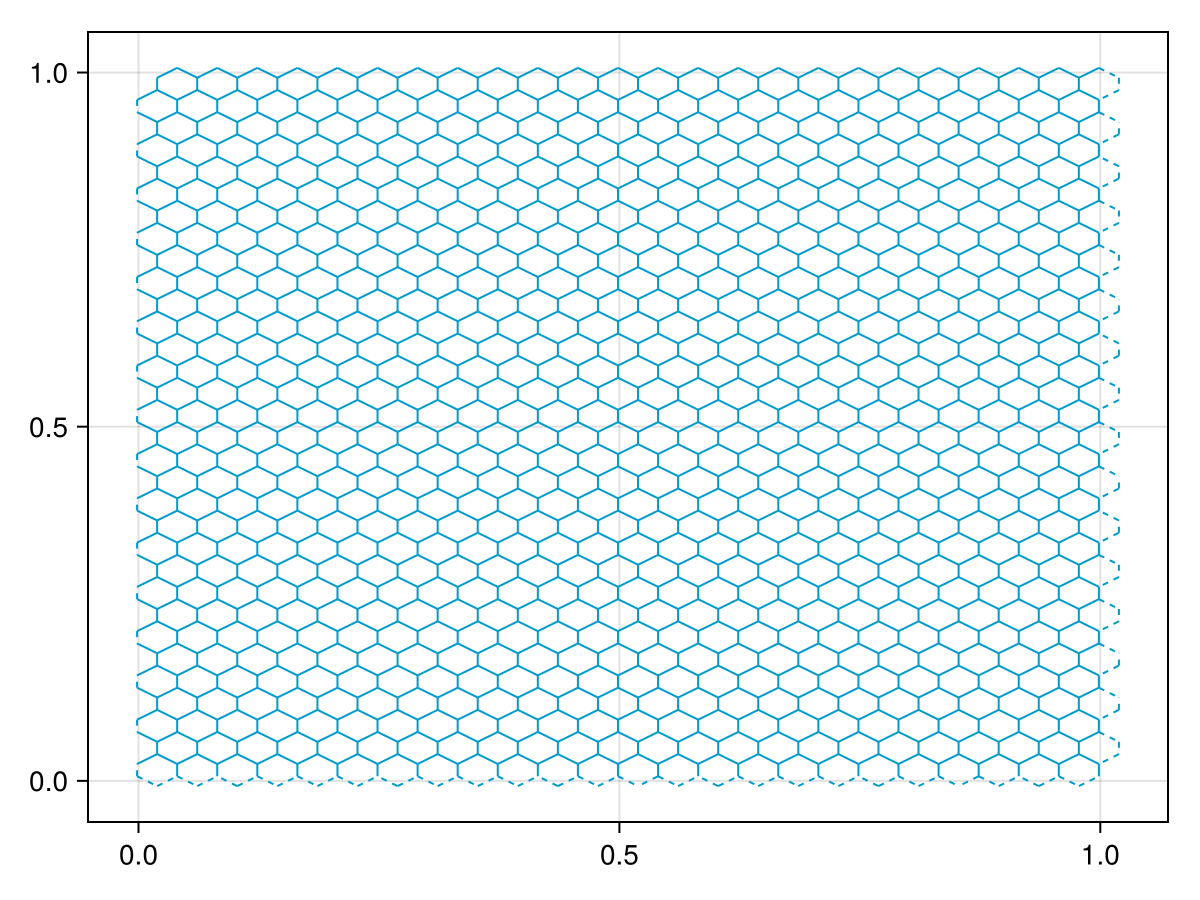

In [8]:
mesh = VoronoiMesh("meshes/mesh4_regular.nc")
fig = Figure()
ax = Axis(fig[1,1])
plotmesh!(ax, mesh)
fig

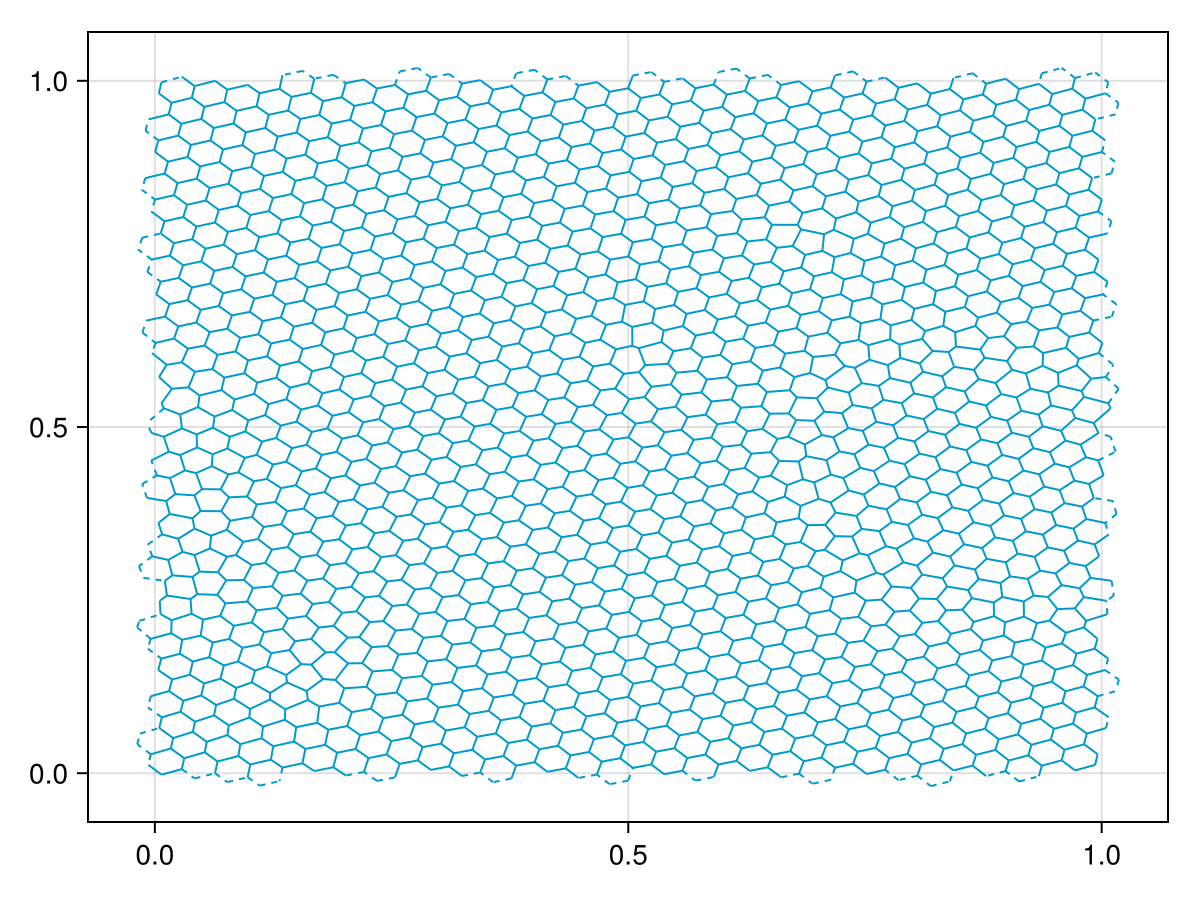

In [7]:
mesh = VoronoiMesh("meshes/mesh4.nc")
fig = Figure()
ax = Axis(fig[1,1])
plotmesh!(ax, mesh)
fig

In [79]:
mesh = VoronoiMesh("meshes/mesh3_regular.nc")
d0 = d0_matrix_primal(mesh)
d1 = d1_matrix_dual(mesh)
star1_diagonal = star(mesh, 1, true)
#star1_lsq1 = hodge_star_lsq_matrix(mesh, true, true)
#star1_lsq2 = hodge_star_lsq_matrix(mesh, true, false)

576×576 Diagonal{Float64, Vector{Float64}}:
 0.666667   ⋅         ⋅         ⋅        …   ⋅         ⋅         ⋅ 
  ⋅        0.666667   ⋅         ⋅            ⋅         ⋅         ⋅ 
  ⋅         ⋅        0.416667   ⋅            ⋅         ⋅         ⋅ 
  ⋅         ⋅         ⋅        0.666667      ⋅         ⋅         ⋅ 
  ⋅         ⋅         ⋅         ⋅            ⋅         ⋅         ⋅ 
  ⋅         ⋅         ⋅         ⋅        …   ⋅         ⋅         ⋅ 
  ⋅         ⋅         ⋅         ⋅            ⋅         ⋅         ⋅ 
  ⋅         ⋅         ⋅         ⋅            ⋅         ⋅         ⋅ 
  ⋅         ⋅         ⋅         ⋅            ⋅         ⋅         ⋅ 
  ⋅         ⋅         ⋅         ⋅            ⋅         ⋅         ⋅ 
 ⋮                                       ⋱                      ⋮
  ⋅         ⋅         ⋅         ⋅            ⋅         ⋅         ⋅ 
  ⋅         ⋅         ⋅         ⋅            ⋅         ⋅         ⋅ 
  ⋅         ⋅         ⋅         ⋅            ⋅         ⋅         ⋅ 
  ⋅   

In [80]:
using LinearAlgebra
G = d1 * star1_diagonal  * d0
0 in [abs(sum(abs.(G[i, :])) - 2*abs(G[i,i])) < 1e-10 for i in axes(G, 1)]


false

In [81]:
all(abs(sum(G[i, :]) - 2*G[i,i]) <= 1e-10 for i in axes(G, 1))

false

In [82]:
[sum(abs.(G[i, :])) <= 2*abs(G[i,i])  for i in axes(G, 1)]

192-element Vector{Bool}:
 1
 1
 1
 1
 0
 1
 1
 1
 0
 1
 ⋮
 1
 1
 1
 0
 1
 1
 1
 1
 1